In [4]:
import pandas as pd
import numpy as np
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt
%pip install pingouin
import pingouin as pg
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline
%pip install variable_inspector


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/9.1 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 49.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/35.3 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━ 34.3/35.3 MB 171.0 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 158.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/12.1 MB ? eta -:--:--

... (49 outputs left out)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


<img src="https://github.com/ethanweed/ethanweed.github.io/blob/master/python-tutorials/images/Nettle_1998_abstract.png?raw=true" width="700"/>

## Data

Nettle recorded:

1. the *number of languages* 
1. the *area* (in km<sup>2</sup>) 
1. the *population* 
1. the *mean growing season* (MGS, in months) 
1. the number of weather stations measuring MGS
1. the standard deviation of the measurements of MGS from the different weather stations in each country.

In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/ethanweed/ethanweed.github.io/master/r-tutorials/data/nettle_1998.csv", sep=";")
df

,Country,Languages,Area,Population,Stations,MGS,GS_SD,Variable_GS,Used_in_1996
0,Algeria,18,2381741,25660,102,6.60,2.29,Y,N
1,Angola,42,1246700,10303,50,6.22,1.87,N,N
2,Australia,234,7713364,17336,134,6.00,4.17,Y,N
3,Bangladesh,37,143998,118745,20,7.40,0.73,N,N
4,Benin,52,112622,4889,7,7.14,0.99,N,Y
...,...,...,...,...,...,...,...,...,...
69,Vietnam,88,331689,68183,40,8.80,1.59,N,N
70,Yemen,6,527968,12302,2,0.00,0.00,N,N
71,Zaire,219,2344858,36672,16,9.44,1.90,N,N
72,Zambia,38,752618,8780,30,5.43,0.67,N,N


In [6]:
# Nettle reports the population data in 1000s, probably to save room in the data table, 
#but that is an unusual number to think about population in, so let's convert to millions. 
#While we're at it, let's convert km2 to millions, so that the number doesn't appear in scientific notation 
#on the x-axis
df['Population'] = df['Population']/1000
df['Area'] = df['Area']/1000000

# look at the first lines of the dataframe
df.head()

,Country,Languages,Area,Population,Stations,MGS,GS_SD,Variable_GS,Used_in_1996
0,Algeria,18,2.381741,25.660,102,6.60,2.29,Y,N
1,Angola,42,1.246700,10.303,50,6.22,1.87,N,N
2,Australia,234,7.713364,17.336,134,6.00,4.17,Y,N
3,Bangladesh,37,0.143998,118.745,20,7.40,0.73,N,N
4,Benin,52,0.112622,4.889,7,7.14,0.99,N,Y


## Plotting Relationships
We can use seaborn to see if there is any clear relationship between these variables. We could start with asking whether there a relationship between countries' *area* and their *number of languages spoken*. We can use the ``sns.regplot`` function to take a quick look.

<Axes: xlabel='Area', ylabel='Languages'>

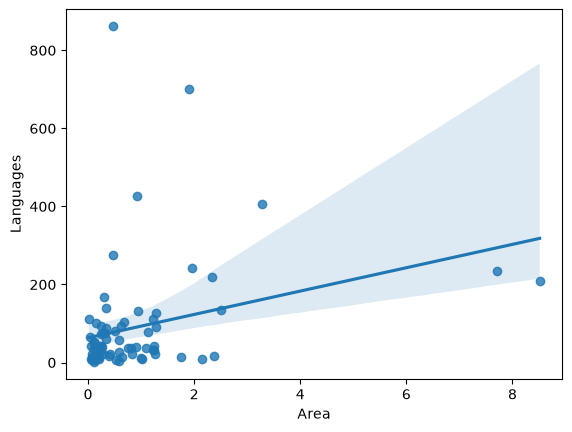

In [7]:
sns.regplot(x = "Area", y = "Languages", data = df)

There does seem to be some sort of relationship here, but it is difficult to see on the plot. A few countries are outliers, and they are pushing all the other data down into the lower-left corner. By transforming the data to a logarithmic scale, we can stretch them out a bit, and make them easier to see. Let's add three more columns to the dataframe, with log-transformed versions of the Population, Area, and Languages data:

In [15]:
# the idea: log transofrmation compresses large values and spreads out small ones
df['Population_log'] = np.log(df['Population'])
df['Area_log'] = np.log(df['Area'])
df['Languages_log'] = np.log(df['Languages'])
df.tail()

,Country,Languages,Area,Population,Stations,MGS,GS_SD,Variable_GS,Used_in_1996,Population_log,Area_log,Languages_log
69,Vietnam,88,0.331689,68.183,40,8.80,1.59,N,N,4.222195,-1.103557,4.477337
70,Yemen,6,0.527968,12.302,2,0.00,0.00,N,N,2.509762,-0.638720,1.791759
71,Zaire,219,2.344858,36.672,16,9.44,1.90,N,N,3.602014,0.852225,5.389072
72,Zambia,38,0.752618,8.780,30,5.43,0.67,N,N,2.172476,-0.284197,3.637586
73,Zimbabwe,18,0.390759,10.019,52,5.29,1.43,N,N,2.304483,-0.939664,2.890372


Now the relationship is a little easier to see:

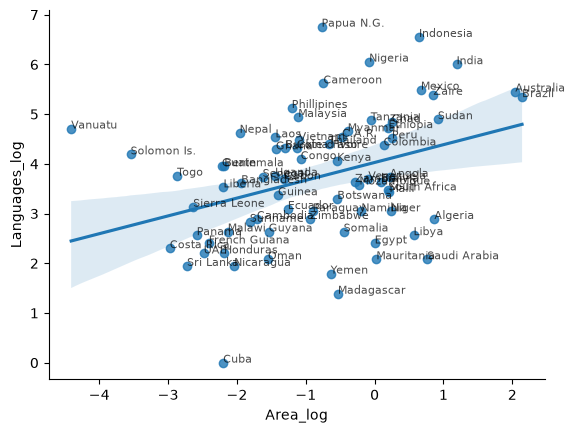

In [16]:
# Plot the log-transformed data
sns.regplot(x = "Area_log", y = "Languages_log", data = df)

# Add labels for each point
for idx, row in df.iterrows():
    plt.annotate(row['Country'], 
                 (row['Area_log'], row['Languages_log']),
                 fontsize=8,
                 alpha=0.7)
    
sns.despine()

## Modelling Number of Languages as a Linear Function of Area

We can see that as the area of a country increases, the number of languages also tends to go up. We can model this more explicitly with a linear regression.

In [17]:
pg.linear_regression(df['Area_log'], df['Languages_log']).round(2)

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,4.03,0.17,23.74,0.0,0.13,0.12,3.69,4.37
1,Area_log,0.36,0.11,3.25,0.0,0.13,0.12,0.14,0.58


## Raw or log-transformed data for the analysis?

The log-transformation makes it easier to see the data, but why use the log-transformed data for our regression analysis? One way to understand this is to look at the *residuals*: the vertical distance between each point and the regression line. If a linear model fits well, the residuals should be scattered evenly around zero, with no pattern and roughly the same spread everywhere.

We can compare the residuals from a model using the raw data with a model using the log-transformed data:

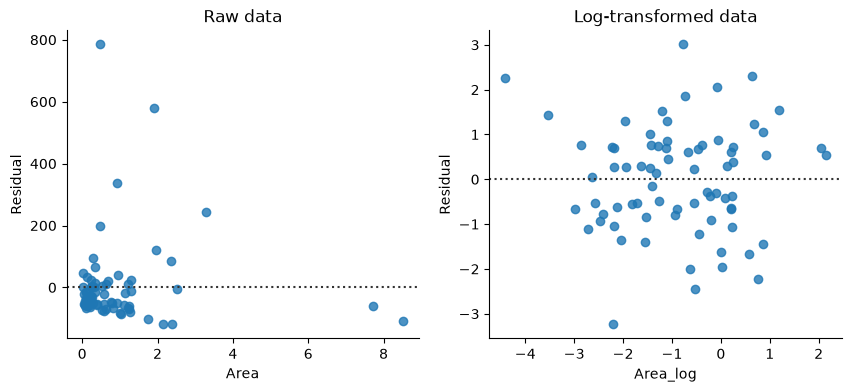

In [18]:
fig, axs = plt.subplots(ncols=2, figsize=(10, 4))
sns.residplot(x="Area", y="Languages", data=df, ax=axs[0])
axs[0].set_title("Raw data")
sns.residplot(x="Area_log", y="Languages_log", data=df, ax=axs[1])
axs[1].set_title("Log-transformed data")
for ax in axs:
    ax.set_ylabel("Residual")
sns.despine()

In the raw data, most countries are bunched up on the left, and a few large countries sit far out on their own. These few points have a lot of influence on where the line goes. The residuals are also lopsided: most sit just below zero, while a handful of countries (e.g. Papua New Guinea, Indonesia) have huge positive residuals. In the log-transformed data, the residuals are spread much more evenly above and below zero, with no obvious pattern.

The log transform also changes what the slope means. With both variables log-transformed, the slope tells us roughly how many *percent* the number of languages changes for each one-percent change in area. A slope of 0.36 means that doubling a country's area goes along with about $2^{0.36} \approx 1.28$ times as many languages, i.e. about 28% more.

## Adding more predictors

But Area isn't the only thing correlated with the number of languages. 

Population size looks like it might also be a relevant factor:

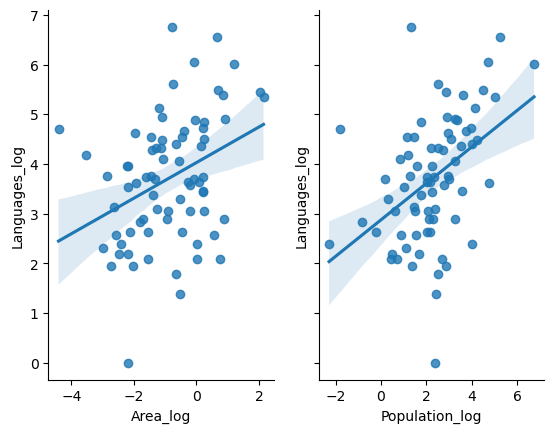

In [53]:
fig, axs = plt.subplots(ncols=2, sharey = True)
sns.regplot(x = "Area_log", y = "Languages_log", data = df, ax=axs[0])
sns.regplot(x = "Population_log", y = "Languages_log", data = df, ax=axs[1])
sns.despine()

## Multiple Regression
By adding Population as a second *predictor variable*, we can estimate the relative importance of both Area and Population in predicting the Number of Languages:

In [54]:
pg.linear_regression(df[['Area_log', 'Population_log']], df['Languages_log']).round(2)

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,3.18,0.34,9.23,0.00,0.22,0.19,2.49,3.86
1,Area_log,0.16,0.13,1.22,0.23,0.22,0.19,-0.10,0.41
2,Population_log,0.29,0.11,2.80,0.01,0.22,0.19,0.09,0.50


## Questions 1
1. Just a moment ago, when we modelled the relationship between (log) area and the (log) number of languages, we got a slope of 0.36. Now it says we have a slope of 0.16. Why? What changed?
2. Before, area was a significant predictor of number of languages (p<0.05). When we add population in, suddenly Area is no longer significant??? What the heck?
3. Which model (the one with just area, or the one with area and population) accounts for more of the variance in the number of languages?

## More predictors

Area and population are not the only predictor variables we have in the data. Let's add in Mean Growing Season as well, and see what happens.

In [55]:
pg.linear_regression(df[['Area_log', 'Population_log', 'MGS']], df['Languages_log']).round(4)

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,2.18,0.37,5.93,0.00,0.41,0.38,1.45,2.91
1,Area_log,0.38,0.12,3.14,0.00,0.41,0.38,0.14,0.62
2,Population_log,0.22,0.09,2.38,0.02,0.41,0.38,0.04,0.41
3,MGS,0.19,0.04,4.74,0.00,0.41,0.38,0.11,0.27


## Questions 2

1. Does the model with three predictors account for more of the variation in number of languages than the models with one or two predictors? How can you tell?
2. Wait... now Area is significant again (p<0.05)? Are you kidding me? What's going on?

## Questions 3
1. In the model with only Area and Population, the slope for Area was 0.16 and not significant. Now that we have added MGS, the slope for Area is 0.38 and significant. Why did adding MGS make Area *more* important, when adding Population made it *less* important?
2. Hint: take a look at the way the variables correlate:

In [56]:
predictors = df[['Area_log', 'Population_log', 'MGS']]
predictors.corr().round(2)

,Area_log,Population_log,MGS
Area_log,1.00,0.57,-0.37
Population_log,0.57,1.00,-0.08
MGS,-0.37,-0.08,1.00
